In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, precision_score, recall_score,
                             f1_score, accuracy_score, confusion_matrix)

df = pd.read_csv('Loan_default.csv')
print(df.shape)
print(df['Default'].value_counts(normalize=True))
print('Missing values:', df.isna().sum().sum())

(255347, 18)
Default
0    0.883872
1    0.116128
Name: proportion, dtype: float64
Missing values: 0


In [3]:
y = df['Default']
ids = df['LoanID']
X = pd.get_dummies(df.drop(columns=['LoanID', 'Default']), drop_first=True).astype(float)

X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, ids, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)

(204277, 24) (51070, 24)


In [4]:
lr = make_pipeline(StandardScaler(),
                   LogisticRegression(class_weight='balanced', max_iter=1000))
lr.fit(X_train, y_train)
lr_prob = lr.predict_proba(X_test)[:, 1]
lr_pred = (lr_prob >= 0.5).astype(int)
print('LR ROC-AUC:', round(roc_auc_score(y_test, lr_prob), 4))

LR ROC-AUC: 0.7532


In [5]:
rf = RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=50,
                            class_weight='balanced_subsample', n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
rf_prob = rf.predict_proba(X_test)[:, 1]
rf_pred = (rf_prob >= 0.5).astype(int)

print('RF ROC-AUC  :', round(roc_auc_score(y_test, rf_prob), 4))
print('Precision   :', round(precision_score(y_test, rf_pred), 4))
print('Recall      :', round(recall_score(y_test, rf_pred), 4))
print('F1          :', round(f1_score(y_test, rf_pred), 4))
print('Accuracy    :', round(accuracy_score(y_test, rf_pred), 4))
print(confusion_matrix(y_test, rf_pred))

RF ROC-AUC  : 0.7555
Precision   : 0.2475
Recall      : 0.6326
F1          : 0.3558
Accuracy    : 0.7339
[[33730 11409]
 [ 2179  3752]]


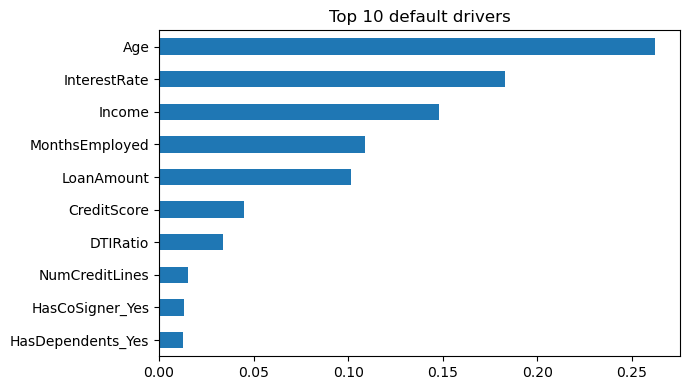

Age                  0.2624
InterestRate         0.1828
Income               0.1481
MonthsEmployed       0.1087
LoanAmount           0.1016
CreditScore          0.0451
DTIRatio             0.0336
NumCreditLines       0.0151
HasCoSigner_Yes      0.0133
HasDependents_Yes    0.0124
dtype: float64


In [6]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
imp.sort_values().plot(kind='barh', figsize=(7, 4), title='Top 10 default drivers')
plt.tight_layout(); plt.show()
print(imp.round(4))

In [7]:
prob_all = rf.predict_proba(X)[:, 1]
out = pd.DataFrame({'LoanID': ids, 'DefaultProb': prob_all.round(4), 'Actual': y})
out['IsTest'] = out['LoanID'].isin(id_test).astype(int)

rank = out['DefaultProb'].rank(pct=True)
out['RiskCategory'] = np.where(rank > 0.8, 'High', np.where(rank > 0.5, 'Medium', 'Low'))
out['RiskOrder'] = out['RiskCategory'].map({'Low': 1, 'Medium': 2, 'High': 3})
out['PredictedDefault'] = (out['DefaultProb'] >= 0.5).astype(int)
out.to_csv('loan_predictions.csv', index=False)

# Sanity check on unseen loans: the High tier should default far more than Low
print(out[out.IsTest == 1].groupby('RiskCategory')['Actual'].mean().round(3))

metrics = pd.DataFrame([
    ['Logistic Regression', roc_auc_score(y_test, lr_prob), precision_score(y_test, lr_pred),
     recall_score(y_test, lr_pred), f1_score(y_test, lr_pred), accuracy_score(y_test, lr_pred)],
    ['Random Forest', roc_auc_score(y_test, rf_prob), precision_score(y_test, rf_pred),
     recall_score(y_test, rf_pred), f1_score(y_test, rf_pred), accuracy_score(y_test, rf_pred)]],
    columns=['Model', 'ROC_AUC', 'Precision', 'Recall', 'F1', 'Accuracy']).round(4)
metrics.to_csv('model_metrics.csv', index=False)

imp.reset_index().rename(columns={'index': 'Feature', 0: 'Importance'}).round(4)\
   .to_csv('feature_importance.csv', index=False)
print(metrics)

RiskCategory
High      0.290
Low       0.044
Medium    0.119
Name: Actual, dtype: float64
                 Model  ROC_AUC  Precision  Recall      F1  Accuracy
0  Logistic Regression   0.7532     0.2196  0.6994  0.3343    0.6765
1        Random Forest   0.7555     0.2475  0.6326  0.3558    0.7339


In [8]:
rows = []
for t in [0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]:
    pred = (rf_prob >= t).astype(int)
    rows.append([t,
                 precision_score(y_test, pred, zero_division=0),
                 recall_score(y_test, pred),
                 f1_score(y_test, pred),
                 pred.mean()])
print(pd.DataFrame(rows, columns=['Threshold', 'Precision', 'Recall', 'F1', 'Share_flagged']).round(3))

   Threshold  Precision  Recall     F1  Share_flagged
0       0.40      0.187   0.809  0.304          0.502
1       0.45      0.214   0.727  0.331          0.394
2       0.50      0.247   0.633  0.356          0.297
3       0.55      0.285   0.523  0.369          0.213
4       0.60      0.327   0.403  0.361          0.143
5       0.65      0.389   0.282  0.327          0.084
6       0.70      0.475   0.172  0.253          0.042


In [9]:
import joblib, os

prob_all = rf.predict_proba(X)[:, 1]
bundle = {
    'model': rf,
    'columns': list(X.columns),
    'cut_medium': float(np.quantile(prob_all, 0.5)),
    'cut_high': float(np.quantile(prob_all, 0.8)),
}
joblib.dump(bundle, 'loan_model.joblib', compress=3)
print(round(os.path.getsize('loan_model.joblib') / 1e6, 1), 'MB')
print(bundle['cut_medium'], bundle['cut_high'])

17.9 MB
0.3997909131435009 0.5590096080438816


In [10]:
import sklearn, joblib, pandas, numpy
print(f"scikit-learn=={sklearn.__version__}")
print(f"joblib=={joblib.__version__}")
print(f"pandas=={pandas.__version__}")
print(f"numpy=={numpy.__version__}")

scikit-learn==1.5.1
joblib==1.4.2
pandas==2.2.2
numpy==1.26.4
